# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Isaiah De Vera, William Keenan, Olympia Sauerwein

**Date:** 11/9/26

In [28]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

1.

In [29]:
df = pd.read_csv('./pierce_county_house_sales.csv')
print(df.head())
print(df.dtypes)
print(df.isnull().sum())

    sale_date  sale_price  house_square_feet  attic_finished_square_feet  \
0  2020-01-02      380000               2157                           0   
1  2020-01-02      383000               2238                           0   
2  2020-01-01      419900               1452                           0   
3  2020-01-02      251660                832                           0   
4  2020-01-02      500000               1780                           0   

   basement_square_feet  attached_garage_square_feet  \
0                     0                          528   
1                     0                          396   
2                     0                            0   
3                     0                            0   
4                   384                          484   

   detached_garage_square_feet  fireplaces        hvac_description  \
0                            0           0  Warm and Cool Air Zone   
1                            0           0              Forced Air

In [30]:
#cleaning

df = df.drop_duplicates()
df.columns = df.columns.str.strip()

numeric_columns = ['sale_price', 'house_square_feet','attic_finished_square_feet','basement_square_feet','attached_garage_square_feet','detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms']
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.dropna(subset=["sale_price"])
df = df[df["sale_price"] > 0]

categorical_columns = ['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality', 'utility_sewer']
for column in categorical_columns:
    df[column] = df[column].str.strip()
    df[column] = df[column].fillna("Unknown")

print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 16768 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   sale_date                    16768 non-null  object
 1   sale_price                   16768 non-null  int64 
 2   house_square_feet            16768 non-null  int64 
 3   attic_finished_square_feet   16768 non-null  int64 
 4   basement_square_feet         16768 non-null  int64 
 5   attached_garage_square_feet  16768 non-null  int64 
 6   detached_garage_square_feet  16768 non-null  int64 
 7   fireplaces                   16768 non-null  int64 
 8   hvac_description             16768 non-null  object
 9   exterior                     16768 non-null  object
 10  interior                     16768 non-null  object
 11  stories                      16768 non-null  int64 
 12  roof_cover                   16768 non-null  object
 13  year_built                   16768 n

         sale_price  house_square_feet  attic_finished_square_feet  \
count  1.676800e+04       16768.000000                16768.000000   
mean   4.612053e+05        1879.174082                   25.014313   
std    2.361158e+05         760.438267                  102.197955   
min    2.000000e+03           1.000000                    0.000000   
25%    3.480000e+05        1320.000000                    0.000000   
50%    4.167250e+05        1774.000000                    0.000000   
75%    5.238815e+05        2351.250000                    0.000000   
max    6.130000e+06        9510.000000                 1212.000000   

       basement_square_feet  attached_garage_square_feet  \
count          16768.000000                 16768.000000   
mean             168.189408                   364.218810   
std              429.462204                   286.647006   
min                0.000000                     0.000000   
25%                0.000000                     0.000000   
50%      

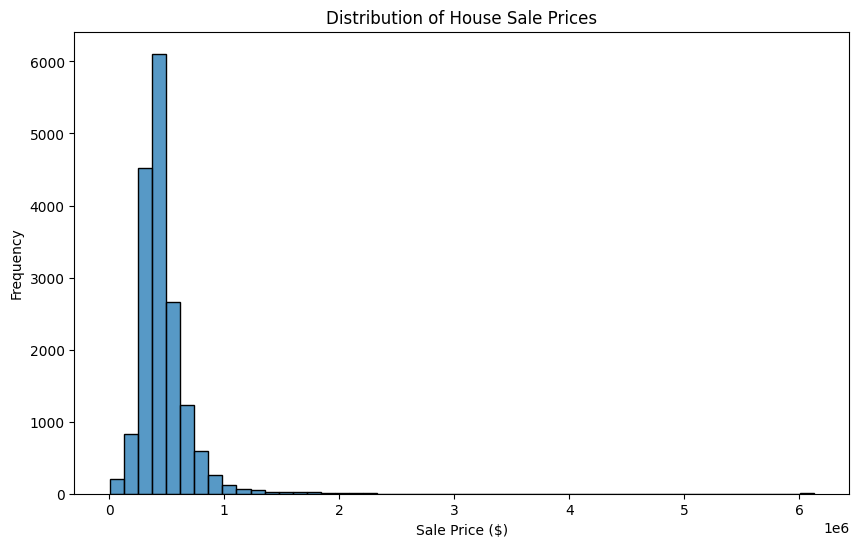

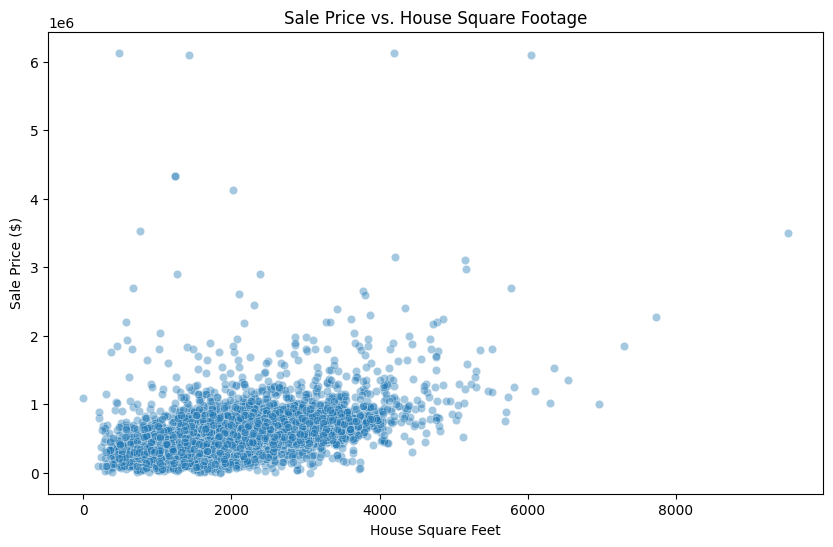

In [31]:
#eda and visualiztion

print(df.describe())
for column in categorical_columns:
    print('\nUnique values in', column)
    print(df[column].unique())

#sales prices histogram
plt.figure(figsize=(10, 6))
sns.histplot(df['sale_price'], bins=50)

plt.title('Distribution of House Sale Prices')
plt.xlabel('Sale Price ($)')
plt.ylabel('Frequency')
plt.show()

#sale price vs sq ft
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x = 'house_square_feet', y='sale_price', alpha=0.4)

plt.title("Sale Price vs. House Square Footage")
plt.xlabel("House Square Feet")
plt.ylabel("Sale Price ($)")
plt.show()


2.

In [32]:
model_df = df

model_df['sale_date'] = pd.to_datetime(model_df['sale_date'], errors='coerce')
model_df['sale_year'] = model_df['sale_date'].dt.year
model_df['sale_month'] = model_df['sale_date'].dt.month
model_df['house_age'] = model_df['sale_year'] - model_df['year_built']
model_df = model_df.drop(columns=['sale_date', 'year_built'])

categorical_columns = ['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality', 'utility_sewer']

model_df = pd.get_dummies(model_df, columns=categorical_columns, drop_first=True, dtype=int)

X = model_df.drop(columns=['sale_price'])
y = model_df['sale_price']

print(X.head())
print(X.dtypes.value_counts())
print('Predictor dimensions:', X.shape)
print('Target dimensions:', y.shape)
print('Missing values:', model_df.isnull().sum().sum())

   house_square_feet  attic_finished_square_feet  basement_square_feet  \
0               2157                           0                     0   
1               2238                           0                     0   
2               1452                           0                     0   
3                832                           0                     0   
4               1780                           0                   384   

   attached_garage_square_feet  detached_garage_square_feet  fireplaces  \
0                          528                            0           0   
1                          396                            0           0   
2                            0                            0           1   
3                            0                            0           0   
4                          484                            0           1   

   stories  bedrooms  bathrooms  sale_year  ...  view_quality_View Good  \
0        2         3         

3.

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


print('X_train shape: ', X_train.shape)
print('y_train shape: ', y_train.shape)
print('X_test shape: ', X_test.shape)
print('y_test shape: ', y_test.shape)

X_train shape:  (13414, 61)
y_train shape:  (13414,)
X_test shape:  (3354, 61)
y_test shape:  (3354,)


4.

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

#model 1: square feet
model1 = LinearRegression()
model1.fit(X_train[['house_square_feet']], y_train)

train_pred1 = model1.predict(X_train[['house_square_feet']])
test_pred1 = model1.predict(X_test[['house_square_feet']])

print('Model 1')
print('Training RMSE:', np.sqrt(mean_squared_error(y_train, train_pred1)))
print('Training R^2:', r2_score(y_train, train_pred1))
print('Testing RMSE:', np.sqrt(mean_squared_error(y_test, test_pred1)))
print('Testing R^2:', r2_score(y_test, test_pred1))


#model 2: age
model2 = LinearRegression()
model2.fit(X_train[['house_age']], y_train)

train_pred2 = model2.predict(X_train[['house_age']])
test_pred2 = model2.predict(X_test[['house_age']])

print('\nModel 2')
print('Training RMSE:', np.sqrt(mean_squared_error(y_train, train_pred2)))
print('Training R^2:', r2_score(y_train, train_pred2))
print('Testing RMSE:', np.sqrt(mean_squared_error(y_test, test_pred2)))
print('Testing R^2:', r2_score(y_test, test_pred2))


#model 3: structural features
features3 = ['house_square_feet', 'bedrooms', 'bathrooms', 'stories', 'house_age', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces']

model3 = LinearRegression()
model3.fit(X_train[features3], y_train)

train_pred3 = model3.predict(X_train[features3])
test_pred3 = model3.predict(X_test[features3])

print('\nModel 3')
print('Training RMSE:', np.sqrt(mean_squared_error(y_train, train_pred3)))
print('Training R^2:', r2_score(y_train, train_pred3))
print('Testing RMSE:', np.sqrt(mean_squared_error(y_test, test_pred3)))
print('Testing R^2:', r2_score(y_test, test_pred3))


#model 4: all predictors
model4 = LinearRegression()
model4.fit(X_train, y_train)

train_pred4 = model4.predict(X_train)
test_pred4 = model4.predict(X_test)

print('\nModel 4')
print('Training RMSE:', np.sqrt(mean_squared_error(y_train, train_pred4)))
print('Training R^2:', r2_score(y_train, train_pred4))
print('Testing RMSE:', np.sqrt(mean_squared_error(y_test, test_pred4)))
print('Testing R^2:', r2_score(y_test, test_pred4))

Model 1
Training RMSE: 209029.29250210428
Training R^2: 0.2628857128273586
Testing RMSE: 164030.9410262745
Testing R^2: 0.3526594071701239

Model 2
Training RMSE: 237560.41336484675
Training R^2: 0.04793045649354155
Testing RMSE: 196022.45425586595
Testing R^2: 0.07552976425366154

Model 3
Training RMSE: 191088.65809780723
Training R^2: 0.3839863308978818
Testing RMSE: 142736.59302086153
Testing R^2: 0.5098241155274985

Model 4
Training RMSE: 163250.9006893927
Training R^2: 0.5503944124140108
Testing RMSE: 133908.72298376032
Testing R^2: 0.5685812409602102


Model 4 did the best with the Lowest RMSE (163250) and the highest R^2 (0.569)

5.

In [ ]:
from sklearn.linear_model import LinearRegression
from statsmodels.nonparametric.smoothers_lowess import lowess

numeric_features = ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet',
                    'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces',
                    'stories', 'bedrooms', 'bathrooms', 'sale_month', 'house_age']

fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.ravel()
for ax, v in zip(axes, numeric_features):
    others = X_train.drop(columns=[v, 'sale_year'])
    res_y = y_train - LinearRegression().fit(others, y_train).predict(others)
    res_x = X_train[v] - LinearRegression().fit(others, X_train[v]).predict(others)

    ax.scatter(res_x, res_y, alpha=0.15, s=6)
    slope, intercept = np.polyfit(res_x, res_y, 1)
    xs = np.linspace(res_x.min(), res_x.max(), 100)
    ax.plot(xs, slope * xs + intercept, 'k--', lw=1.5, label='linear fit')
    smooth = lowess(res_y, res_x, frac=0.4)           # a smooth curve makes any bend easy to see
    ax.plot(smooth[:, 0], smooth[:, 1], 'r', lw=2, label='LOWESS')
    lo, hi = np.percentile(res_y, [0.5, 99.5])
    ax.set_ylim(lo * 1.2, hi * 1.2)
    ax.set_title(v)
    ax.set_xlabel(f'{v} (residual)')
    ax.set_ylabel('sale_price (residual)')
axes[0].legend()
axes[-1].axis('off')
plt.tight_layout()
plt.show()

v = 'house_square_feet'
others = X_train.drop(columns=[v, 'sale_year'])
res_y = y_train - LinearRegression().fit(others, y_train).predict(others)
res_x = X_train[v] - LinearRegression().fit(others, X_train[v]).predict(others)
print('Partial-plot slope:', np.polyfit(res_x, res_y, 1)[0])
print('Model 4 coefficient:', pd.Series(model4.coef_, index=X_train.columns)[v])

There are several significant non-linearities which can be seen in the correlation plots. house_square_feet curves upward, with the price premium per extra square ft being larger for big houses. house_age is roughly U-shaped because newer and older houses both sell for more than middle aged ones, so a line completely hides a real effect. basement_square_feet is concave, as prices seems to rise up to 1,250 sq ft and then flatten. In contrast attached_garage_square_feet is convex, as it starts flat and then rises more quickly for larger garages.

6.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, FunctionTransformer

Xtr, Xte = X_train.drop(columns=['sale_year']), X_test.drop(columns=['sale_year'])   # constant column

area_cols = ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet',
             'attached_garage_square_feet', 'detached_garage_square_feet']
core = ['house_square_feet', 'basement_square_feet', 'attached_garage_square_feet',
        'bedrooms', 'bathrooms', 'stories', 'house_age', 'fireplaces']
wins_cols = ['house_square_feet', 'bedrooms', 'bathrooms', 'house_age']

def ihs_areas(D):
    """Inverse hyperbolic sine compresses long right tails and accepts zeros (unlike log)."""
    D = D.copy()
    D['house_age'] = D['house_age'].clip(lower=0)          # a few sales pre-date the build year
    for c in area_cols:
        D[c] = np.arcsinh(D[c])
    return D

class Winsorizer(BaseEstimator, TransformerMixin):
    """Cap columns at the 1.5-IQR fences, learned from the training data only."""
    def __init__(self, cols):
        self.cols = cols
    def fit(self, D, y=None):
        q1, q3 = np.percentile(D[self.cols], [25, 75], axis=0)
        self.lo_, self.hi_ = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        return self
    def transform(self, D):
        D = D.copy()
        D[self.cols] = np.clip(D[self.cols].to_numpy(float), self.lo_, self.hi_)
        return D

def make_features():
    return make_pipeline(
        FunctionTransformer(ihs_areas),
        Winsorizer(wins_cols),
        ColumnTransformer([('poly', make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                                                  StandardScaler()), core)], remainder='passthrough'))

model5 = TransformedTargetRegressor(make_pipeline(make_features(), LinearRegression()),
                                    func=np.arcsinh, inverse_func=np.sinh)
model5.fit(Xtr, y_train)
train_pred5, test_pred5 = model5.predict(Xtr), model5.predict(Xte)

print('Model 5 (complex)')
print('Training RMSE:', np.sqrt(mean_squared_error(y_train, train_pred5)))
print('Training R^2:', r2_score(y_train, train_pred5))
print('Testing RMSE:', np.sqrt(mean_squared_error(y_test, test_pred5)))
print('Testing R^2:', r2_score(y_test, test_pred5))

folds = KFold(n_splits=5, shuffle=True, random_state=3001)
f3 = ['house_square_feet', 'bedrooms', 'bathrooms', 'stories', 'house_age', 'attic_finished_square_feet',
      'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces']
def cv_rmse(model, cols):
    s = cross_validate(model, X_train[cols], y_train, cv=folds, scoring='neg_root_mean_squared_error')
    return -s['test_score'].mean()

comparison = pd.DataFrame({
    'Model': ['1: sq ft', '2: age', '3: structural', '4: all predictors', '5: complex'],
    'CV RMSE': [cv_rmse(LinearRegression(), ['house_square_feet']), cv_rmse(LinearRegression(), ['house_age']),
                cv_rmse(LinearRegression(), f3), cv_rmse(LinearRegression(), list(X_train.columns)),
                -cross_validate(model5, Xtr, y_train, cv=folds, scoring='neg_root_mean_squared_error')['test_score'].mean()],
    'Test RMSE': [np.sqrt(mean_squared_error(y_test, p)) for p in [test_pred1, test_pred2, test_pred3, test_pred4, test_pred5]],
    'Train R^2': [r2_score(y_train, p) for p in [train_pred1, train_pred2, train_pred3, train_pred4, train_pred5]],
    'Test R^2': [r2_score(y_test, p) for p in [test_pred1, test_pred2, test_pred3, test_pred4, test_pred5]],
})
print(comparison.round(3).to_string(index=False))

To make a more complex model, I compressed the price scale with an inverse hyperbolic sine (applied ot price and square-footage columns) and capped exterem values for sq ft, bedrooms, bathrooms, and age leaving only a few unusual houses to potentially lay away from the line of best fit. After reflecting in question 5 that house size and age do not follow a linear pattern, I added squared terms to include hte curves and combined feautures (like sq ft x bathrooms) allowing for one feature's effect to depend on another without significant error. I then compared models using cross-validation on the training data and looked at the test set. This resulted in the test RMSE dropping from 133.9k dollars to 118.7k dollars and test R^2 rising from 0.569 to 0.661, while the training R^2 remaining nearly unchanged, proving that hte model isn't simply memorizing the training data. In other models when exterme values are not capped, the preidctions jump substantaly, so it is crucial that extereme values are controlled in addition to adding features.

7.

Models 1 and 2 underfit because they are too simple. Their errors are significant both on the training and test data sets. As we added more features, the models got stronger. Adding the test R^2 helped in Model 3, adding the predictors in Model 4, and eventually the complex model 5 (0.66, test RMSE dropping from 164k dollars in model 1 to 119k dollars). Overfitting was never a notable problem in these models. Model 5 was clearly the strongest due to its performance on the test data and its training and test resutls being so close. I did note that the outliers can skew the the more flexible model, so it was important to cap them. I also learned that models must be compared on data that they were not training on, beacuse training resutls will favor the most complicated model. Finally, I noticed taht even with the best model, some of the price variation remains unexplained, particularly in this sitaution when we're missing data like location, lot size, etc.

8.

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV

lasso_model = TransformedTargetRegressor(
    make_pipeline(make_features(), StandardScaler(), Lasso(max_iter=20000, tol=1e-3)),
    func=np.arcsinh, inverse_func=np.sinh)

search = GridSearchCV(lasso_model,
                      {'regressor__lasso__alpha': [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]},
                      cv=folds, scoring='neg_root_mean_squared_error')
search.fit(Xtr, y_train)
best = search.best_estimator_
print('Selected alpha:', search.best_params_['regressor__lasso__alpha'])
print('CV RMSE:', -search.best_score_)

train_pred6, test_pred6 = best.predict(Xtr), best.predict(Xte)
print('\nLasso')
print('Training RMSE:', np.sqrt(mean_squared_error(y_train, train_pred6)))
print('Training R^2:', r2_score(y_train, train_pred6))
print('Testing RMSE:', np.sqrt(mean_squared_error(y_test, test_pred6)))
print('Testing R^2:', r2_score(y_test, test_pred6))

rows = []
for a, cv_mse in zip(search.cv_results_['param_regressor__lasso__alpha'], -search.cv_results_['mean_test_score']):
    m = lasso_model.set_params(regressor__lasso__alpha=a).fit(Xtr, y_train)
    p = m.predict(Xte)
    rows.append({'alpha': a, 'CV RMSE': cv_mse, 'Test RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'Test R^2': r2_score(y_test, p), 'Nonzero slopes': int((m.regressor_[-1].coef_ != 0).sum())})
print(pd.DataFrame(rows).round(4).to_string(index=False))

mean_cv, std_cv = -search.cv_results_['mean_test_score'], search.cv_results_['std_test_score']
alphas = np.array(search.cv_results_['param_regressor__lasso__alpha'], dtype=float)
best_i = mean_cv.argmin()
alpha_sparse = alphas[mean_cv <= mean_cv[best_i] + std_cv[best_i] / np.sqrt(folds.get_n_splits())].max()
sparse = lasso_model.set_params(regressor__lasso__alpha=alpha_sparse).fit(Xtr, y_train)
pred_s = sparse.predict(Xte)
print(f'\nSparser Lasso, alpha = {alpha_sparse}: test RMSE {np.sqrt(mean_squared_error(y_test, pred_s)):,.0f}, test R^2 {r2_score(y_test, pred_s):.4f}')

poly_names = sparse.regressor_[0].named_steps['columntransformer'].named_transformers_['poly'][0].get_feature_names_out(core)
names = list(poly_names) + [c for c in Xtr.columns if c not in core]
coefs = pd.Series(sparse.regressor_[-1].coef_, index=names)
selected = coefs[coefs != 0].sort_values(key=abs, ascending=False)
print(f'Nonzero coefficients: {len(selected)} of {len(coefs)}')
print(selected.round(4).to_string())
print('\nDropped:', list(coefs[coefs == 0].index))

~Q8 analysis

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]